In [1]:
ls

Analyser.ipynb
bi-encoder_BAAI-bge-large-en-v1.5_cleaned.csv
bi-encoder_Qwen-Qwen3-Embedding-0.6B_cleaned.csv
bi-encoder_Qwen-Qwen3-Embedding-4B_cleaned.csv
bi-encoder_Qwen-Qwen3-Embedding-8B_cleaned.csv
bi-encoder_sentence-transformers-all-MiniLM-L6-v2_cleaned.csv
colbert_colbert-ir-colbertv2.0_cleaned.csv
colbert_lightonai-Reason-ModernColBERT_cleaned.csv
colbert_LiquidAI-LFM2-ColBERT-350M_cleaned.csv
colbert_mixedbread-ai-mxbai-colbert-large-v1_cleaned.csv
cross-encoder_BAAI-bge-reranker-v2-m3_cleaned.csv
cross-encoder_mixedbread-ai-mxbai-rerank-large-v2_cleaned.csv
cross-encoder_Qwen-Qwen3-Reranker-0.6B_cleaned.csv
cross-encoder_Qwen-Qwen3-Reranker-4B_cleaned.csv
cross-encoder_Qwen-Qwen3-Reranker-8B_cleaned.csv


In [6]:
import pandas as pd
import numpy as np


In [7]:
df = pd.read_csv("cross-encoder_Qwen-Qwen3-Reranker-4B_cleaned.csv")

In [9]:
score_cols = [c for c in df.columns if c.endswith("_scores")]
S = df[score_cols].to_numpy(dtype=float)

df["gap"] = S.max(axis=1) - np.median(S, axis=1)
df["is_specialist"] = df["expected_service"] != "general"

print("k =", len(score_cols))
df[["expected_service", "gap"]]

k = 3


,expected_service,gap
0,abstract_algebra,15.6875
1,abstract_algebra,18.2500
2,abstract_algebra,8.1250
3,abstract_algebra,15.8125
4,abstract_algebra,6.5000
...,...,...
395,general,0.5625
396,general,0.8125
397,general,0.4375
398,general,0.6250


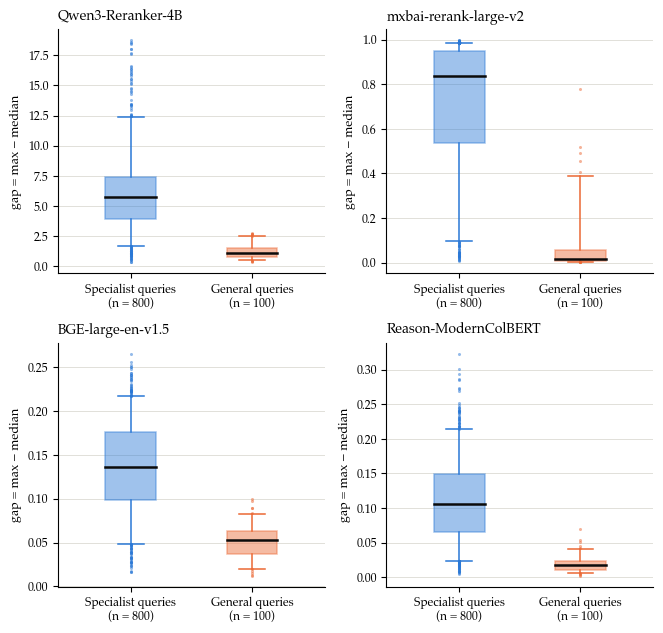

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from matplotlib import font_manager
import logging
logging.getLogger("fontTools.subset").setLevel(logging.ERROR)

plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Palatino Linotype", "Palatino", "TeX Gyre Pagella", "P052",
                   "URW Palladio L", "Book Antiqua", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 9,
    "axes.titlesize": 10, "axes.labelsize": 9,
    "xtick.labelsize": 8.5, "ytick.labelsize": 8.5,
    "pdf.fonttype": 42, "ps.fonttype": 42,
})

FILES = {
    "Qwen3-Reranker-4B":     "cross-encoder_Qwen-Qwen3-Reranker-4B_cleaned.csv",
    "mxbai-rerank-large-v2": "cross-encoder_mixedbread-ai-mxbai-rerank-large-v2_cleaned.csv",
    "BGE-large-en-v1.5":     "bi-encoder_BAAI-bge-large-en-v1.5_cleaned.csv",
    "Reason-ModernColBERT":  "colbert_lightonai-Reason-ModernColBERT_cleaned.csv",
}

BLUE, ORANGE, INK, GRID = "#2a78d6", "#eb6834", "#0b0b0b", "#e1e0d9"

fig, axes = plt.subplots(2, 2, figsize=(6.7, 6.4), facecolor="white")
for ax, (name, path) in zip(axes.ravel(), FILES.items()):
    d = pd.read_csv(path)
    S = d[[c for c in d.columns if c.endswith("_scores")]].to_numpy(dtype=float)
    g = S.max(axis=1) - np.median(S, axis=1)                  # gap = max - median
    spec = (d["expected_service"] != "general").to_numpy()    # True = specialist query

    for i, (data, col) in enumerate(((g[spec], BLUE), (g[~spec], ORANGE))):
        ax.boxplot(data, positions=[i], widths=0.42, patch_artist=True, whis=(5, 95), zorder=3,
                   flierprops=dict(marker="o", ms=2.2, mfc=col, mec="none", alpha=.5),
                   medianprops=dict(color=INK, lw=1.8),
                   whiskerprops=dict(color=col, lw=1.1), capprops=dict(color=col, lw=1.1),
                   boxprops=dict(facecolor=col, alpha=.45, edgecolor=col, lw=1.1))

    ax.set_xticks([0, 1])
    ax.set_xticklabels([f"Specialist queries\n(n = {spec.sum()})",
                        f"General queries\n(n = {(~spec).sum()})"])
    ax.set_xlim(-0.6, 1.6)
    ax.set_ylabel("gap = max − median")
    ax.set_title(name, loc="left", fontweight="bold")
    ax.grid(axis="y", color=GRID, lw=.7); ax.set_axisbelow(True)
    for s in ("top", "right"): ax.spines[s].set_visible(False)

fig.tight_layout()
fig.savefig("gap_boxplots_k8.pdf", bbox_inches="tight", facecolor="white")
fig.savefig("gap_boxplots_k8.png", dpi=600, bbox_inches="tight", facecolor="white")
plt.show()